# RAPPORT COMPLET
## Analyse financière des banques de l’UMOA
**Burkina Faso · Exercices 2021 à 2023 · Montants en millions FCFA**

Source des données : *Fascicule BCEAO des bilans et comptes de résultat des banques de l’UMOA 2023 / Base Excel (Bilans_et_Comptes_de_Resultat_Exhaustif.xlsx)*

La variable `bank_code` de la première cellule de code choisit la banque ouverte par défaut. La synthèse finale est générée automatiquement pour toutes les banques disponibles; les codes sont affichés après le chargement du classeur.

---

## 1. Synthèse et points clés
Cette première partie présente une vue d’ensemble de la situation financière de la banque avant l’analyse détaillée des parties suivantes.

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import HTML, display as _display

REPORT_TABLE_STYLES = [
    {'selector': 'table', 'props': [('border-collapse', 'collapse'), ('width', '100%'), ('color', '#e7eee9')]},
    {'selector': 'thead th', 'props': [('background-color', '#39433d'), ('color', '#f4f7f5'), ('padding', '7px'), ('text-align', 'right')]},
    {'selector': 'tbody td', 'props': [('background-color', '#292e2b'), ('color', '#e7eee9'), ('border-bottom', '1px solid #4b554f'), ('padding', '6px'), ('text-align', 'right')]},
    {'selector': 'tbody th', 'props': [('background-color', '#343c37'), ('color', '#a7d8bd'), ('border-bottom', '1px solid #4b554f'), ('padding', '6px'), ('text-align', 'left')]},
]


def style_report_table(dataframe, formatters=None, precision=2):
    styled = dataframe.style.format(na_rep='—', precision=precision, thousands=' ')
    if formatters:
        styled = styled.format(formatters)
    return styled.set_table_styles(REPORT_TABLE_STYLES).set_properties(**{'vertical-align': 'top'})


def display(value, *args, **kwargs):
    if isinstance(value, pd.DataFrame):
        value = style_report_table(value)
    return _display(value, *args, **kwargs)


# Palette et typographie du rapport
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.facecolor'] = 'white'

# Le fichier est recherche dans le dossier courant puis dans ses dossiers parents
excel_name = 'Bilans_et_Comptes_de_Resultat_Exhaustif.xlsx'
search_dirs = [Path.cwd(), *Path.cwd().parents]
excel_matches = [folder / excel_name for folder in search_dirs if (folder / excel_name).exists()]
if not excel_matches:
    local_excels = list(Path.cwd().glob('*.xlsx'))
    if len(local_excels) == 1:
        excel_matches = local_excels
if not excel_matches:
    raise FileNotFoundError(
        f"Classeur introuvable : {excel_name}. Placez-le dans le dossier du projet ou adaptez excel_name."
    )
excel_path = excel_matches[0]

sheet_name = 'Toutes_Les_Donnees'
df_all = pd.read_excel(excel_path, sheet_name=sheet_name)
required_columns = {'CODE BANQUE', 'POSTE / RUBRIQUE'}
missing_columns = required_columns.difference(df_all.columns)
if missing_columns:
    raise ValueError(f"Colonnes absentes du classeur : {sorted(missing_columns)}")

df_all['CODE BANQUE'] = df_all['CODE BANQUE'].astype(str).str.strip().str.upper()
df_all['_RUBRIQUE_NORM'] = df_all['POSTE / RUBRIQUE'].astype(str).str.strip().str.upper()
available_banks = sorted(df_all['CODE BANQUE'].dropna().unique())

# Modifier cette valeur pour choisir une autre banque parmi les codes affiches.
bank_code = 'BADF'
if bank_code.upper() not in available_banks:
    raise ValueError(f"Banque {bank_code!r} absente. Codes disponibles : {available_banks}")
df_bank = df_all.loc[df_all['CODE BANQUE'] == bank_code.upper()].copy()

years = [str(year) for year in (2021, 2022, 2023) if str(year) in df_bank.columns]
if not years:
    raise ValueError('Aucune colonne annuelle 2021-2023 n’a ete trouvee dans le classeur.')

# Valeurs manquantes ou marquees '-' restent numeriquement nulles

def get_val(rubrique, year):
    labels = [rubrique] if isinstance(rubrique, str) else rubrique
    for label in labels:
        key = str(label).strip().upper()
        rows = df_bank.loc[df_bank['_RUBRIQUE_NORM'] == key, year]
        if not rows.empty:
            numeric_values = pd.to_numeric(rows, errors='coerce').dropna()
            return float(numeric_values.iloc[0]) if not numeric_values.empty else 0.0
    return 0.0


def safe_ratio(numerator, denominator, scale=100):
    if denominator is None or not np.isfinite(denominator) or denominator == 0:
        return np.nan
    return numerator / denominator * scale


# Postes de bilan et du compte de resultat disponibles dans le fichier
postes = {
    'total_actif': "TOTAL DE L'ACTIF",
    'total_passif': 'TOTAL DU PASSIF',
    'creances_clientele': 'CREANCES SUR LA CLIENTELE',
    'depots_clientele': "DETTES A L'EGARD DE LA CLIENTELE",
    'dettes_interbank': 'DETTES INTERBANCAIRES ET ASSIMILEES',
    'caisse_bceao': 'CAISSE, BANQUE CENTRALE, CCP',
    'creances_interbank': 'CREANCES INTERBANCAIRES ET ASSIMILEES',
    'effets_publics': 'EFFETS PUBLICS ET VALEURS ASSIMILEES',
    'equity': 'CAPITAUX PROPRES ET RESSOURCES ASSIMILEES',
    'resultat_net': 'RESULTAT NET',
    'pnb': ['PRODUIT NET BANCAIRE', 'PRODUITS NET BANCAIRE'],
    'charges_exploitation': "CHARGES GENERALES D'EXPLOITATION",
    'amortissements': 'DOTATIONS AUX AMORTISSEMENTS ET AUX DEPRECIATIONS DES IMMOBILISATIONS INCORPORELLES ET CORPORELLES',
    'cout_risque': 'COUT DU RISQUE',
    'interets_produits': ['INTERETS ET PRODUITS ASSIMILEES', 'INTERETS ET PRODUITS ASSIMILES'],
    'interets_charges': 'INTERETS ET CHARGES ASSIMILEES',
    'commissions_produits': 'COMMISSIONS (PRODUITS)',
    'commissions_charges': 'COMMISSIONS (CHARGES)',
    'subventions': 'SUBVENTIONS D\'INVESTISSEMENT',
    'gains_actifs_immobilises': ['GAINS OU PERTES NETS SUR ACTIFS IMMOBILISES (+/-)', 'GAINS OU PERTES NETS SUR ACTIFS IMMOBILISES'],
    'resultat_brut_exploitation': 'RESULTAT BRUT D\'EXPLOITATION',
    'resultat_exploitation': 'RESULTAT D\'EXPLOITATION',
}
valeurs = {nom: {year: get_val(poste, year) for year in years} for nom, poste in postes.items()}

# Variables historiques conservees pour la suite du rapport
for nom, values in valeurs.items():
    globals()[nom] = values
capitaux_propres = equity

print(f"Donnees chargees : {bank_code} | {excel_path.name} | {', '.join(years)}")
print(f"Codes banques disponibles : {', '.join(available_banks)}")
print(f"Postes de la banque : {len(df_bank)}")

Donnees chargees : BADF | Bilans_et_Comptes_de_Resultat_Exhaustif.xlsx | 2021, 2022, 2023
Codes banques disponibles : BADF, BCB, BHS, BPBF, CDS, FBNBANK, IB BANK, WBI
Postes de la banque : 61


In [5]:
last_year = years[-1]
previous_year = years[-2] if len(years) > 1 else None


def format_amount(value):
    return '—' if not np.isfinite(value) else f'{value:,.0f}'.replace(',', ' ')


def annual_change(values):
    if previous_year is None:
        return 'Pas de comparaison annuelle'
    previous_value = values[previous_year]
    current_value = values[last_year]
    if not np.isfinite(previous_value) or not np.isfinite(current_value) or previous_value == 0:
        return 'Variation non calculable'
    if previous_value * current_value < 0:
        return 'Changement de signe'
    change = (current_value - previous_value) / abs(previous_value) * 100
    return f'{change:+.1f} % sur un an'


kpis = [
    ('Total bilan', total_actif[last_year], total_actif),
    ('PNB', pnb[last_year], pnb),
    ('Résultat net', resultat_net[last_year], resultat_net),
    ('Capitaux propres', capitaux_propres[last_year], capitaux_propres),
]

repere_values = {
    'Transformation': (safe_ratio(creances_clientele[last_year], depots_clientele[last_year]), 'max', 100),
    'Solvabilité comptable': (safe_ratio(capitaux_propres[last_year], total_actif[last_year]), 'min', 8),
    'ROA': (safe_ratio(resultat_net[last_year], total_actif[last_year]), 'min', 1),
    'Coût d’exploitation / PNB': (
        safe_ratio(charges_exploitation[last_year] + amortissements[last_year], pnb[last_year]), 'max', 60
    ),
    'Coût du risque / crédits': (
        safe_ratio(cout_risque[last_year], creances_clientele[last_year]), 'max', 2
    ),
}
repere_valides = [
    value <= threshold if direction == 'max' else value >= threshold
    for value, direction, threshold in repere_values.values()
    if np.isfinite(value)
]
repere_text = (
    f"{sum(repere_valides)}/{len(repere_valides)} repères indicatifs atteints"
    if repere_valides else 'Aucun repère calculable'
)
if resultat_net[last_year] < 0 or capitaux_propres[last_year] <= 0:
    assessment = 'Points de vigilance'
    assessment_detail = 'Résultat net négatif ou capitaux propres non positifs sur le dernier exercice.'
elif repere_valides and sum(repere_valides) / len(repere_valides) >= 0.75:
    assessment = 'Situation plutôt favorable'
    assessment_detail = 'La majorité des repères calculables est atteinte.'
else:
    assessment = 'Situation à suivre'
    assessment_detail = 'Certains repères calculables appellent une attention particulière.'

cards_html = ''.join(
    f"<div class='kpi-card'><div class='kpi-label'>{label} {last_year}</div>"
    f"<div class='kpi-value'>{format_amount(value)}</div>"
    f"<div class='kpi-foot'>{annual_change(values)}</div></div>"
    for label, value, values in kpis
)
display(HTML(f"""
<style>
.financial-summary {{ color: #e7eee9; font-family: 'Segoe UI', sans-serif; }}
.financial-summary .kpi-grid {{ display: grid; grid-template-columns: repeat(auto-fit, minmax(155px, 1fr)); gap: 6px; margin: 12px 0 18px; }}
.financial-summary .kpi-card {{ background: #343c37; border-top: 2px solid #82c49b; padding: 11px 13px; min-height: 72px; }}
.financial-summary .kpi-label {{ color: #c3cec7; font-size: 11px; }}
.financial-summary .kpi-value {{ color: #a7d8bd; font-size: 21px; font-weight: 700; margin: 4px 0; }}
.financial-summary .kpi-foot {{ color: #c3cec7; font-size: 10px; }}
.financial-summary .assessment {{ display: grid; grid-template-columns: 90px 1fr; border: 1px solid #82c49b; margin: 10px 0 22px; }}
.financial-summary .assessment-mark {{ display: grid; place-items: center; background: #82c49b; color: #26332b; font-size: 15px; font-weight: 700; text-align: center; padding: 10px; }}
.financial-summary .assessment-copy {{ padding: 11px 14px; }}
.financial-summary .assessment-copy strong {{ display: block; color: #a7d8bd; font-size: 16px; margin-bottom: 4px; }}
.financial-summary .assessment-copy span {{ color: #c3cec7; font-size: 11px; }}
@media (max-width: 480px) {{ .financial-summary .assessment {{ grid-template-columns: 1fr; }} }}
</style>
<div class='financial-summary'>
  <div><strong>{bank_code}</strong> · Exercice {last_year} · Montants en millions FCFA</div>
  <div class='kpi-grid'>{cards_html}</div>
  <div class='assessment'>
    <div class='assessment-mark'>{repere_text}</div>
    <div class='assessment-copy'><strong>Appréciation générale : {assessment}</strong>
      <span>{assessment_detail} Lecture indicative, non assimilable à une notation officielle.</span></div>
  </div>
</div>
"""))

postes_actif = {
    'Caisse, banque centrale, CCP': 'CAISSE, BANQUE CENTRALE, CCP',
    'Effets publics et valeurs assimilées': 'EFFETS PUBLICS ET VALEURS ASSIMILEES',
    'Créances interbancaires et assimilées': 'CREANCES INTERBANCAIRES ET ASSIMILEES',
    'Créances sur la clientèle': 'CREANCES SUR LA CLIENTELE',
    'Obligations et autres titres à revenu fixe': 'OBLIGATIONS ET AUTRES TITRES A REVENU FIXE',
    'Actions et autres titres à revenu variable': 'ACTIONS ET AUTRES TITRES A REVENU VARIABLE',
    'Actionnaires ou associés': 'ACTIONNAIRES OU ASSOCIES',
    'Autres actifs': 'AUTRES ACTIFS',
    'Comptes de régularisation (actif)': 'COMPTES DE REGULARISATION (ACTIF)',
    'Participations et autres titres détenus à long terme': 'PARTICIPATIONS ET AUTRES TITRES DETENUS A LONG TERME',
    'Parts dans les entreprises liées': 'PARTS DANS LES ENTREPRISES LIEES',
    'Prêts subordonnés': 'PRETS SUBORDONNES',
    'Immobilisations incorporelles': 'IMMOBILISATIONS INCORPORELLES',
    'Immobilisations corporelles': 'IMMOBILISATIONS CORPORELLES',
    'Total actif': "TOTAL DE L'ACTIF",
}
df_actif_detail = pd.DataFrame(
    {year: {label: get_val(poste, year) for label, poste in postes_actif.items()} for year in years}
)
for year_index in range(1, len(years)):
    previous, current = years[year_index - 1], years[year_index]
    variation = (df_actif_detail[current] - df_actif_detail[previous]) / df_actif_detail[previous].abs().replace(0, np.nan) * 100
    df_actif_detail[f'Δ% {current}'] = variation
df_actif_detail[years] = df_actif_detail[years].round().astype('int64')

display(HTML('<h3 style="color:#a7d8bd; margin:8px 0">Actif · montants et variations annuelles</h3>'))
display(
    df_actif_detail.style
    .format({f'Δ% {year}': lambda value: '—' if pd.isna(value) else f'{value:+.1f} %' for year in years[1:]})
    .set_table_styles([
        {'selector': 'table', 'props': [('border-collapse', 'collapse'), ('width', '100%'), ('color', '#e7eee9')]},
        {'selector': 'thead th', 'props': [('background-color', '#39433d'), ('color', '#f4f7f5'), ('padding', '6px'), ('text-align', 'right')]},
        {'selector': 'tbody td', 'props': [('background-color', '#292e2b'), ('border-bottom', '1px solid #4b554f'), ('padding', '5px'), ('text-align', 'right')]},
        {'selector': 'tbody th', 'props': [('background-color', '#292e2b'), ('border-bottom', '1px solid #4b554f'), ('padding', '5px'), ('text-align', 'left')]},
    ])
)

,2021,2022,2023,Δ% 2022,Δ% 2023
"Caisse, banque centrale, CCP",3010,7666,7971,+154.7 %,+4.0 %
Effets publics et valeurs assimilées,57305,78762,80293,+37.4 %,+1.9 %
Créances interbancaires et assimilées,3821,3501,1390,-8.4 %,-60.3 %
Créances sur la clientèle,93249,120683,86748,+29.4 %,-28.1 %
Obligations et autres titres à revenu fixe,0,0,0,—,—
Actions et autres titres à revenu variable,0,0,0,—,—
Actionnaires ou associés,0,0,0,—,—
Autres actifs,173,155,2899,-10.4 %,+1770.3 %
Comptes de régularisation (actif),0,0,0,—,—
Participations et autres titres détenus à long terme,23,23,23,+0.0 %,+0.0 %


## 2. Dynamique du bilan et du compte de résultat

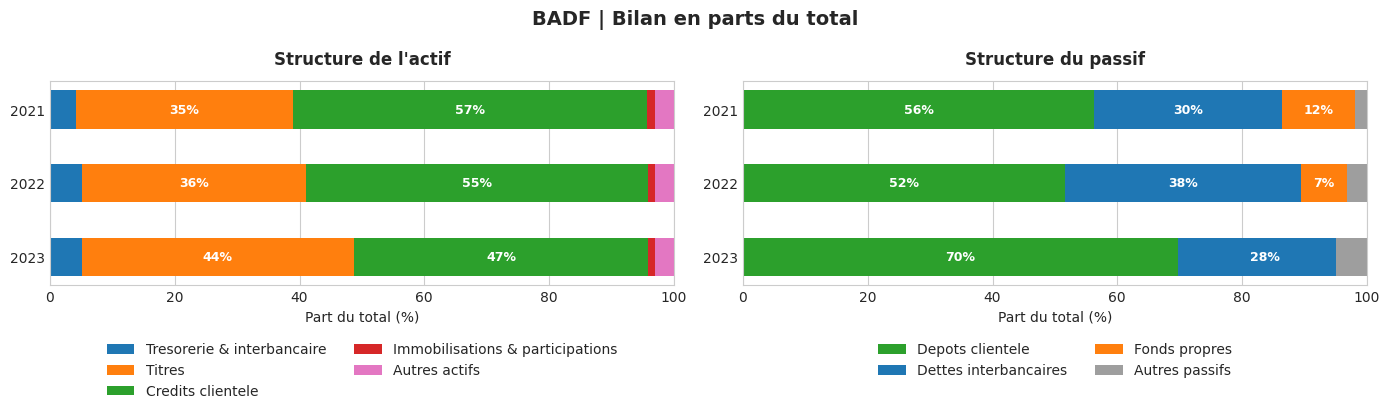

In [6]:
# Figures 1 et 2 : structure de l'actif et du passif
categories_actif = [
    'Tresorerie & interbancaire', 'Titres', 'Credits clientele',
    'Immobilisations & participations', 'Autres actifs'
]
colors_actif = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#e377c2']
categories_passif = ['Depots clientele', 'Dettes interbancaires', 'Fonds propres', 'Autres passifs']
colors_passif = ['#2ca02c', '#1f77b4', '#ff7f0e', '#9e9e9e']

data_actif = []
data_passif = []
for year in years:
    tresorerie = caisse_bceao[year] + creances_interbank[year]
    titres = (
        effets_publics[year]
        + get_val('OBLIGATIONS ET AUTRES TITRES A REVENU FIXE', year)
        + get_val('ACTIONS ET AUTRES TITRES A REVENU VARIABLE', year)
    )
    immobilisations = sum(get_val(poste, year) for poste in [
        'IMMOBILISATIONS CORPORELLES',
        'IMMOBILISATIONS INCORPORELLES',
        'PARTICIPATIONS ET AUTRES TITRES DETENUS A LONG TERME',
        'PARTS DANS LES ENTREPRISES LIEES',
    ])
    actif_autres = total_actif[year] - (tresorerie + titres + creances_clientele[year] + immobilisations)
    data_actif.append([
        safe_ratio(tresorerie, total_actif[year]),
        safe_ratio(titres, total_actif[year]),
        safe_ratio(creances_clientele[year], total_actif[year]),
        safe_ratio(immobilisations, total_actif[year]),
        safe_ratio(actif_autres, total_actif[year]),
    ])

    passif_autres = total_passif[year] - (
        depots_clientele[year] + dettes_interbank[year] + capitaux_propres[year]
    )
    data_passif.append([
        safe_ratio(depots_clientele[year], total_passif[year]),
        safe_ratio(dettes_interbank[year], total_passif[year]),
        safe_ratio(capitaux_propres[year], total_passif[year]),
        safe_ratio(passif_autres, total_passif[year]),
    ])

df_pct_actif = pd.DataFrame(data_actif, index=years, columns=categories_actif).fillna(0)
df_pct_passif = pd.DataFrame(data_passif, index=years, columns=categories_passif).fillna(0)
df_structure = pd.concat({'Actif (% total actif)': df_pct_actif, 'Passif (% total passif)': df_pct_passif}, axis=1)

def draw_stacked_structure(axis, data, categories, colors, title):
    left = np.zeros(len(years))
    for category, color in zip(categories, colors):
        values = data[category].to_numpy(dtype=float)
        axis.barh(years, values, left=left, label=category, color=color, height=0.52)
        for index, value in enumerate(values):
            if value >= 6:
                axis.text(left[index] + value / 2, index, f'{value:.0f}%', ha='center', va='center', color='white', fontweight='bold', fontsize=9)
        left += values
    axis.set_title(title, fontsize=12, fontweight='bold', pad=12)
    axis.set_xlim(0, 100)
    axis.set_xlabel('Part du total (%)')
    axis.invert_yaxis()

fig, (ax_actif, ax_passif) = plt.subplots(1, 2, figsize=(14, 4.5))
draw_stacked_structure(ax_actif, df_pct_actif, categories_actif, colors_actif, "Structure de l'actif")
draw_stacked_structure(ax_passif, df_pct_passif, categories_passif, colors_passif, 'Structure du passif')
ax_actif.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False)
ax_passif.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False)
fig.suptitle(f'{bank_code} | Bilan en parts du total', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

df_parts_postes = pd.concat([
    df_pct_actif.T.assign(Bilan='Actif · % du total actif'),
    df_pct_passif.T.assign(Bilan='Passif · % du total passif'),
]).rename_axis('Poste').reset_index()
df_parts_postes = df_parts_postes[['Bilan', 'Poste', *years]].set_index(['Bilan', 'Poste'])
display(HTML(f'<h3 style="color:#a7d8bd;margin:14px 0 6px">Part de chaque poste dans le bilan · {bank_code}</h3>'))
display(style_report_table(
    df_parts_postes,
    formatters={year: '{:.2f} %' for year in years},
))

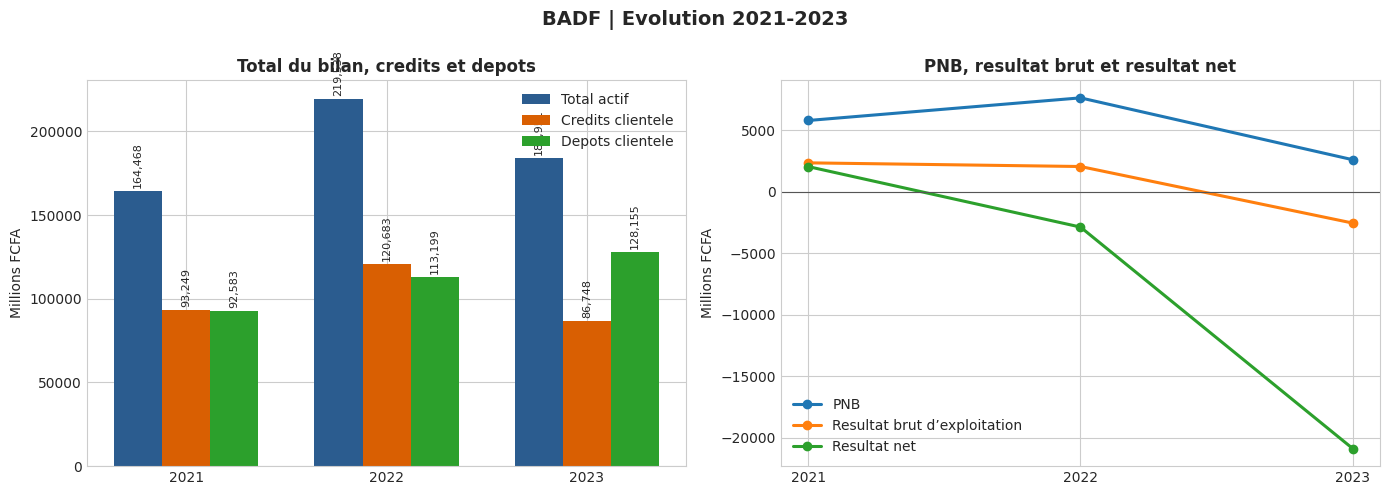

,2021,2022,2023,Variation 2021-2022 (%),Variation 2022-2023 (%)
Total actif,164 468,219 538,183 951,33.50,-16.20
Total passif,164 468,219 536,183 949,33.50,-16.20
Credits clientele,93 249,120 683,86 748,29.40,-28.10
Depots clientele,92 583,113 199,128 155,22.30,13.20
PNB,5 773,7 611,2 586,31.80,-66.00
Resultat brut d’exploitation,2 334,2 036,-2 557,-12.80,-225.60
Resultat net,2 030,-2 882,-20 870,-242.00,624.10


In [8]:
# Figures 3 et 4 : bilan, credits, depots et resultats
fig, (ax_bilan, ax_resultats) = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(years))
width = 0.24
series_bilan = {
    'Total actif': total_actif,
    'Credits clientele': creances_clientele,
    'Depots clientele': depots_clientele,
}
colors_bilan = ['#2b5c8f', '#d95f02', '#2ca02c']
for offset, ((label, values), color) in enumerate(zip(series_bilan.items(), colors_bilan)):
    bars = ax_bilan.bar(x + (offset - 1) * width, [values[year] for year in years], width, label=label, color=color)
    ax_bilan.bar_label(bars, labels=[f'{bar.get_height():,.0f}' for bar in bars], padding=2, fontsize=8, rotation=90)
ax_bilan.set_title('Total du bilan, credits et depots', fontsize=12, fontweight='bold')
ax_bilan.set_ylabel('Millions FCFA')
ax_bilan.set_xticks(x, years)
ax_bilan.legend(frameon=False)

resultat_net_compte = {year: get_val('RESULTAT NET', year) for year in years}
series_resultats = {
    'PNB': pnb,
    'Resultat brut d’exploitation': resultat_brut_exploitation,
    'Resultat net': resultat_net_compte,
}
for label, values in series_resultats.items():
    ax_resultats.plot(years, [values[year] for year in years], marker='o', linewidth=2.2, markersize=6, label=label)
ax_resultats.axhline(0, color='#555555', linewidth=0.8)
ax_resultats.set_title('PNB, resultat brut et resultat net', fontsize=12, fontweight='bold')
ax_resultats.set_ylabel('Millions FCFA')
ax_resultats.legend(frameon=False)
fig.suptitle(f'{bank_code} | Evolution 2021-2023', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

montants_bilan = pd.DataFrame({
    'Total actif': total_actif,
    'Total passif': total_passif,
    'Credits clientele': creances_clientele,
    'Depots clientele': depots_clientele,
    'PNB': pnb,
    'Resultat brut d’exploitation': resultat_brut_exploitation,
    'Resultat net': resultat_net_compte,
}, index=years).T
variations = montants_bilan.pct_change(axis=1) * 100
display(montants_bilan.round(0).astype('int64').assign(**{
    f'Variation {years[i-1]}-{years[i]} (%)': variations[years[i]].round(1)
    for i in range(1, len(years))
}))

## 3. Ratios de structure
Transformation, liquidité, levier et solvabilité.

Ratios de structure, rentabilite et efficacite (en %, sauf multiplicateur)


,Formule,Reference,2021,2022,2023,Statut 2023
Ratio,,,,,,
Transformation,Credits clientele / depots clientele,Maximum 100 %,100.72,106.61,67.69,Conforme
Liquidite du bilan (proxy),(caisse + interbancaire + effets publics) / ressources exigibles,Repere 30 %; approximation sans echeances,45.11,45.83,49.95,Conforme
Solvabilite comptable (proxy),Capitaux propres et ressources assimilees / total actif,Repere indicatif 8 %,11.70,7.45,-2.45,Sous le repere
Solvabilite globale reglementaire,Fonds propres effectifs / actifs ponderes des risques,"Minimum 11,5 %; RWA absents",—,—,—,Non calculable
CET1,Fonds propres CET1 / actifs ponderes des risques,"Minimum 7,5 %; CET1 et RWA absents",—,—,—,Non calculable
Tier 1,Fonds propres Tier 1 / actifs ponderes des risques,"Minimum 8,5 %; Tier 1 et RWA absents",—,—,—,Non calculable
Levier reglementaire,Tier 1 / exposition totale,Minimum 3 %; Tier 1 absent,—,—,—,Non calculable
ROA,Resultat net / total actif,Repere 1 %,1.23,-1.31,-11.35,Sous le repere
ROE,Resultat net / capitaux propres,Repere 10 %,10.55,-17.61,462.95,Non interpretable : fonds propres <= 0


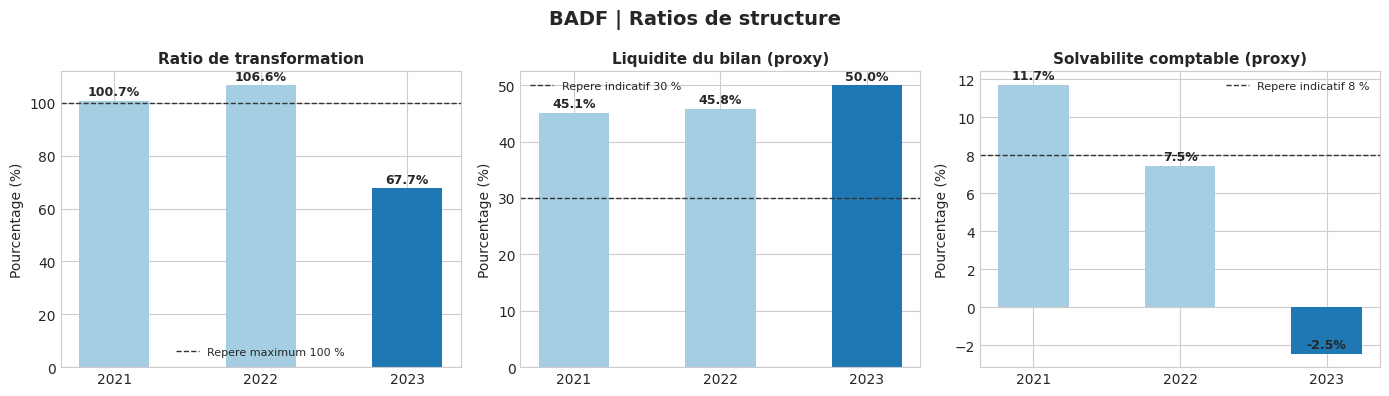

In [9]:
# Ratios de structure et de liquidite
transfo = {year: safe_ratio(creances_clientele[year], depots_clientele[year]) for year in years}
actifs_liquides_proxy = {
    year: caisse_bceao[year] + creances_interbank[year] + effets_publics[year]
    for year in years
}
ressources_exigibles_proxy = {
    year: get_val('BANQUES CENTRALES, CCP', year)
    + dettes_interbank[year] + depots_clientele[year]
    for year in years
}
liquidite_bilan_proxy = {
    year: safe_ratio(actifs_liquides_proxy[year], ressources_exigibles_proxy[year])
    for year in years
}
solvabilite_bilan = {
    year: safe_ratio(capitaux_propres[year], total_actif[year])
    for year in years
}

# Ratios de rentabilite et d'efficacite calcules depuis les postes du classeur
roa = {year: safe_ratio(resultat_net[year], total_actif[year]) for year in years}
roe = {year: safe_ratio(resultat_net[year], capitaux_propres[year]) for year in years}
multiplicateur = {
    year: safe_ratio(total_actif[year], capitaux_propres[year], scale=1)
    for year in years
}
ratio_cout_exploitation = {
    year: safe_ratio(charges_exploitation[year] + amortissements[year], pnb[year])
    for year in years
}
ratio_cout_risque = {
    year: safe_ratio(cout_risque[year], creances_clientele[year])
    for year in years
}
marge_nette = {year: safe_ratio(resultat_net[year], pnb[year]) for year in years}
marge_interets_pnb = {
    year: safe_ratio(interets_produits[year] - interets_charges[year], pnb[year])
    for year in years
}
commissions_nettes_pnb = {
    year: safe_ratio(commissions_produits[year] - commissions_charges[year], pnb[year])
    for year in years
}
pnb_actif = {year: safe_ratio(pnb[year], total_actif[year]) for year in years}

ratio_values = {
    'Transformation': (transfo, 'Credits clientele / depots clientele', 'Maximum 100 %'),
    'Liquidite du bilan (proxy)': (liquidite_bilan_proxy, '(caisse + interbancaire + effets publics) / ressources exigibles', 'Repere 30 %; approximation sans echeances'),
    'Solvabilite comptable (proxy)': (solvabilite_bilan, 'Capitaux propres et ressources assimilees / total actif', 'Repere indicatif 8 %'),
    'Solvabilite globale reglementaire': ({year: np.nan for year in years}, 'Fonds propres effectifs / actifs ponderes des risques', 'Minimum 11,5 %; RWA absents'),
    'CET1': ({year: np.nan for year in years}, 'Fonds propres CET1 / actifs ponderes des risques', 'Minimum 7,5 %; CET1 et RWA absents'),
    'Tier 1': ({year: np.nan for year in years}, 'Fonds propres Tier 1 / actifs ponderes des risques', 'Minimum 8,5 %; Tier 1 et RWA absents'),
    'Levier reglementaire': ({year: np.nan for year in years}, 'Tier 1 / exposition totale', 'Minimum 3 %; Tier 1 absent'),
    'ROA': (roa, 'Resultat net / total actif', 'Repere 1 %'),
    'ROE': (roe, 'Resultat net / capitaux propres', 'Repere 10 %'),
    'Multiplicateur Du Pont': (multiplicateur, 'Total actif / capitaux propres', 'Sans seuil'),
    'Cout d’exploitation / PNB': (ratio_cout_exploitation, '(charges generales + amortissements) / PNB', 'Repere maximum 60 %'),
    'Cout du risque / credits': (ratio_cout_risque, 'Cout du risque / credits clientele', 'Repere maximum 2 %'),
    'Marge nette': (marge_nette, 'Resultat net / PNB', 'Sans seuil'),
    'Marge nette d’interets / PNB': (marge_interets_pnb, '(produits d’interets - charges d’interets) / PNB', 'Sans seuil'),
    'Commissions nettes / PNB': (commissions_nettes_pnb, '(commissions produits - commissions charges) / PNB', 'Sans seuil'),
    'PNB / total actif': (pnb_actif, 'PNB / total actif', 'Sans seuil'),
}


def ratio_status(value, reference):
    if not np.isfinite(value):
        return 'Non calculable'
    if 'Maximum' in reference or 'maximum' in reference:
        limit = float(reference.split('%', 1)[0].replace(',', '.').split()[-1])
        return 'Conforme' if value <= limit else 'A surveiller'
    if 'Repere' in reference or 'Minimum' in reference:
        limit = float(reference.split('%', 1)[0].replace(',', '.').split()[-1])
        return 'Conforme' if value >= limit else 'Sous le repere'
    return 'Information'

rows = []
for label, (values, formula, reference) in ratio_values.items():
    row = {'Ratio': label, 'Formule': formula, 'Reference': reference}
    row.update({year: values[year] for year in years})
    row['Statut ' + years[-1]] = ratio_status(values[years[-1]], reference)
    rows.append(row)
df_ratios = pd.DataFrame(rows).set_index('Ratio')
if capitaux_propres[years[-1]] <= 0:
    df_ratios.loc['ROE', 'Statut ' + years[-1]] = 'Non interpretable : fonds propres <= 0'
print('Ratios de structure, rentabilite et efficacite (en %, sauf multiplicateur)')
display(df_ratios.round(2))

# Courbes des principaux ratios de structure
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
ratio_charts = [
    (transfo, 'Ratio de transformation', 'Repere maximum 100 %', 100),
    (liquidite_bilan_proxy, 'Liquidite du bilan (proxy)', 'Repere indicatif 30 %', 30),
    (solvabilite_bilan, 'Solvabilite comptable (proxy)', 'Repere indicatif 8 %', 8),
]
for axis, (values, title, reference_label, reference_value) in zip(axes, ratio_charts):
    plotted = [values[year] for year in years]
    bars = axis.bar(years, plotted, color=['#a6cee3', '#a6cee3', '#1f78b4'], width=0.48)
    axis.axhline(reference_value, color='#333333', linestyle='--', linewidth=1, label=reference_label)
    axis.set_title(title, fontsize=11, fontweight='bold')
    axis.set_ylabel('Pourcentage (%)')
    axis.legend(frameon=False, fontsize=8)
    for bar, value in zip(bars, plotted):
        if np.isfinite(value):
            axis.annotate(f'{value:.1f}%', (bar.get_x() + bar.get_width() / 2, value), xytext=(0, 4), textcoords='offset points', ha='center', fontsize=9, fontweight='bold')
fig.suptitle(f'{bank_code} | Ratios de structure', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 4. Rentabilité : ROA, ROE et effet de levier

Attention : le ROE 2023 est mathematiquement calcule, mais non interpretable car les fonds propres sont negatifs.


,Formule,2021,2022,2023,Statut 2023
Ratio,,,,,
ROE,Resultat net / capitaux propres,10.55,-17.61,462.95,Non interpretable : fonds propres <= 0


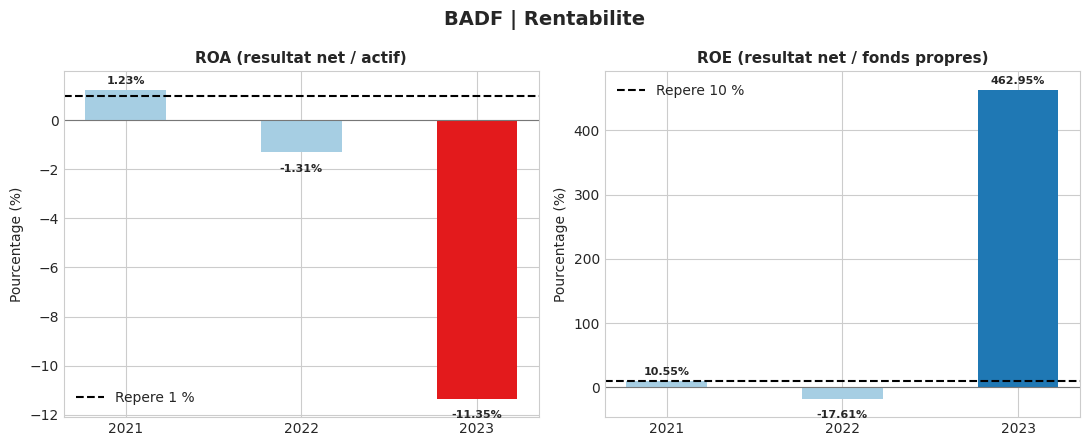

Decomposition Du Pont : ROE = ROA x multiplicateur (attention si les fonds propres sont negatifs).


,ROA (%),Multiplicateur (x),ROE comptable (%),Capitaux propres (millions FCFA)
2021,1.23,8.55,10.55,19 246.00
2022,-1.31,13.42,-17.61,16 362.00
2023,-11.35,-40.81,462.95,-4 508.00


In [10]:
# ROA, ROE et decomposition Du Pont
if capitaux_propres[years[-1]] <= 0:
    df_ratios.loc['ROE', 'Statut ' + years[-1]] = 'Non interpretable : fonds propres <= 0'
    print(f"Attention : le ROE {years[-1]} est mathematiquement calcule, mais non interpretable car les fonds propres sont negatifs.")
    display(df_ratios.loc[['ROE'], ['Formule', *years, 'Statut ' + years[-1]]])

fig, (ax_roa, ax_roe) = plt.subplots(1, 2, figsize=(11, 4.5))
for axis, values, title, benchmark, color in [
    (ax_roa, roa, 'ROA (resultat net / actif)', 1.0, '#e31a1c'),
    (ax_roe, roe, 'ROE (resultat net / fonds propres)', 10.0, '#1f78b4'),
]:
    plotted = [values[year] for year in years]
    bars = axis.bar(years, plotted, color=['#a6cee3', '#a6cee3', color], width=0.46)
    axis.axhline(benchmark, color='black', linestyle='--', label=f'Repere {benchmark:g} %')
    axis.axhline(0, color='#777777', linewidth=0.8)
    axis.set_title(title, fontsize=11, fontweight='bold')
    axis.set_ylabel('Pourcentage (%)')
    axis.legend(frameon=False)
    span = max(max(plotted), benchmark) - min(min(plotted), 0)
    padding = max(span * 0.06, 0.5)
    axis.set_ylim(min(min(plotted), 0) - padding, max(max(plotted), benchmark) + padding)
    for bar, value in zip(bars, plotted):
        axis.annotate(f'{value:.2f}%', (bar.get_x() + bar.get_width() / 2, value), xytext=(0, 4 if value >= 0 else -14), textcoords='offset points', ha='center', fontsize=8, fontweight='bold')
fig.suptitle(f'{bank_code} | Rentabilite', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

df_dupont = pd.DataFrame({
    'ROA (%)': [roa[year] for year in years],
    'Multiplicateur (x)': [multiplicateur[year] for year in years],
    'ROE comptable (%)': [roe[year] for year in years],
    'Capitaux propres (millions FCFA)': [capitaux_propres[year] for year in years],
}, index=years)
print('Decomposition Du Pont : ROE = ROA x multiplicateur (attention si les fonds propres sont negatifs).')
display(df_dupont.round(2))

Indicateurs d’exploitation (en %, sauf indication contraire)


,Formule,Reference,2021,2022,2023,Statut 2023
Ratio,,,,,,
Marge nette,Resultat net / PNB,Sans seuil,35.16 %,-37.87 %,-807.04 %,Information
Coefficient d’exploitation,(charges generales + amortissements) / PNB,Repere maximum 60 %,47.31 %,66.15 %,179.66 %,A surveiller
Coût du risque / crédits,Cout du risque / credits clientele,Repere maximum 2 %,0.28 %,4.01 %,21.03 %,A surveiller
Marge nette d’intérêts / PNB,(produits d’interets - charges d’interets) / PNB,Sans seuil,71.23 %,75.89 %,52.59 %,Information
Commissions nettes / PNB,(commissions produits - commissions charges) / PNB,Sans seuil,13.55 %,9.21 %,16.90 %,Information
PNB / total actif,PNB / total actif,Sans seuil,3.51 %,3.47 %,1.41 %,Information


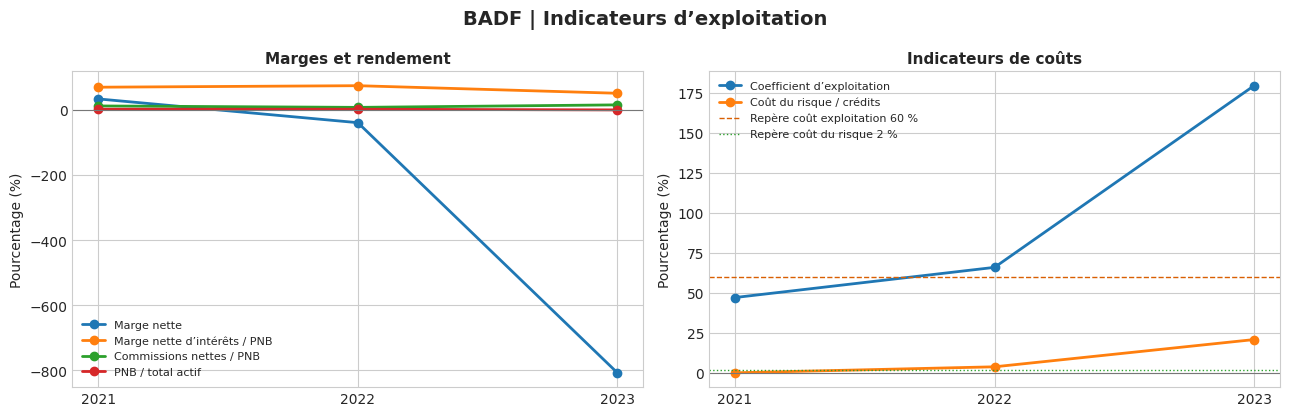

In [11]:
indicateurs_exploitation = [
    'Marge nette',
    'Cout d’exploitation / PNB',
    'Cout du risque / credits',
    'Marge nette d’interets / PNB',
    'Commissions nettes / PNB',
    'PNB / total actif',
]
noms_indicateurs_exploitation = {
    'Marge nette': 'Marge nette',
    'Cout d’exploitation / PNB': 'Coefficient d’exploitation',
    'Cout du risque / credits': 'Coût du risque / crédits',
    'Marge nette d’interets / PNB': 'Marge nette d’intérêts / PNB',
    'Commissions nettes / PNB': 'Commissions nettes / PNB',
    'PNB / total actif': 'PNB / total actif',
}
df_indicateurs_exploitation = df_ratios.loc[indicateurs_exploitation].rename(
    index=noms_indicateurs_exploitation
)
print('Indicateurs d’exploitation (en %, sauf indication contraire)')
display(
    df_indicateurs_exploitation.style
    .format({year: '{:.2f} %' for year in years})
    .set_table_styles([
        {'selector': 'table', 'props': [('border-collapse', 'collapse'), ('width', '100%')]},
        {'selector': 'thead th', 'props': [('background-color', '#39433d'), ('color', '#f4f7f5'), ('padding', '7px')]},
        {'selector': 'tbody td', 'props': [('background-color', '#292e2b'), ('color', '#e7eee9'), ('border-bottom', '1px solid #4b554f'), ('padding', '6px')]},
        {'selector': 'tbody th', 'props': [('background-color', '#292e2b'), ('color', '#a7d8bd'), ('border-bottom', '1px solid #4b554f'), ('padding', '6px'), ('text-align', 'left')]},
    ])
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
indicateurs_marges = {
    'Marge nette': marge_nette,
    'Marge nette d’interets / PNB': marge_interets_pnb,
    'Commissions nettes / PNB': commissions_nettes_pnb,
    'PNB / total actif': pnb_actif,
}
for label, values in indicateurs_marges.items():
    axes[0].plot(years, [values[year] for year in years], marker='o', linewidth=2, label=noms_indicateurs_exploitation[label])
axes[0].axhline(0, color='#777777', linewidth=0.8)
axes[0].set_title('Marges et rendement', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Pourcentage (%)')
axes[0].legend(frameon=False, fontsize=8)

indicateurs_couts = {
    'Cout d’exploitation / PNB': ratio_cout_exploitation,
    'Cout du risque / credits': ratio_cout_risque,
}
for label, values in indicateurs_couts.items():
    axes[1].plot(years, [values[year] for year in years], marker='o', linewidth=2, label=noms_indicateurs_exploitation[label])
axes[1].axhline(0, color='#777777', linewidth=0.8)
axes[1].axhline(60, color='#d95f02', linestyle='--', linewidth=1, label='Repère coût exploitation 60 %')
axes[1].axhline(2, color='#2ca02c', linestyle=':', linewidth=1, label='Repère coût du risque 2 %')
axes[1].set_title('Indicateurs de coûts', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Pourcentage (%)')
axes[1].legend(frameon=False, fontsize=8)
fig.suptitle(f'{bank_code} | Indicateurs d’exploitation', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Test de faillite et ratios de stress
Évaluation de la capacité d'absorption des risques.

Stress tests calcules a partir des capitaux comptables Excel; valeurs en millions FCFA sauf ratios.
Les estimations de coussin prudentiel selon les RWA proxy figurent dans la section suivante.


,2021,2022,2023
Perte d’actifs absorbable sur fonds propres comptables (%),11.70,7.45,-2.45
Defauts de credits absorbables sur fonds propres comptables (%),20.64,13.56,-5.20
Perte nette critique (millions FCFA),-19 246.00,-16 362.00,4 508.00
PNB critique (millions FCFA),-16 256.00,-6 483.00,27 400.00
Baisse du PNB tolerable (%),381.59,185.18,-959.55
Cout du risque critique (millions FCFA),22 289.00,18 939.00,-6 567.00


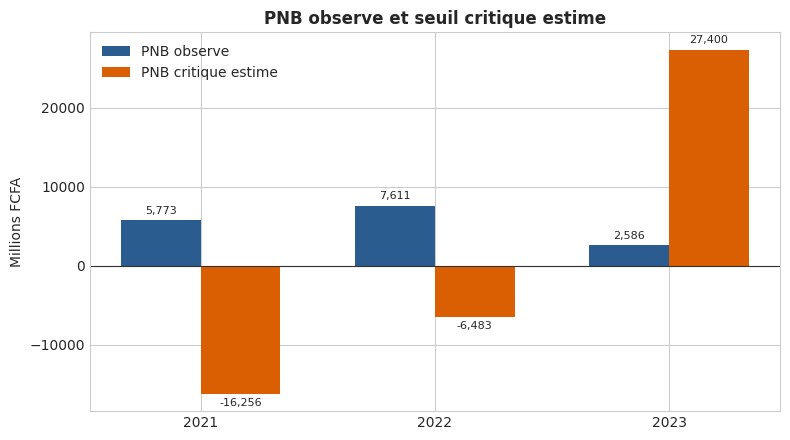

In [12]:
# Stress test : capacite d'absorption et seuil de rentabilite
perte_actifs_absorbable = {
    year: safe_ratio(capitaux_propres[year], total_actif[year])
    for year in years
}
defauts_credits_absorbables = {
    year: safe_ratio(capitaux_propres[year], creances_clientele[year])
    for year in years
}
perte_nette_critique = {year: -capitaux_propres[year] for year in years}
pnb_critique = {
    year: (
        -capitaux_propres[year]
        - subventions[year]
        + charges_exploitation[year]
        + amortissements[year]
        + cout_risque[year]
        - gains_actifs_immobilises[year]
    )
    for year in years
}
baisse_pnb_tolerable = {
    year: safe_ratio(pnb[year] - pnb_critique[year], pnb[year])
    for year in years
}
cout_risque_critique = {
    year: (
        pnb[year]
        + subventions[year]
        - charges_exploitation[year]
        - amortissements[year]
        + gains_actifs_immobilises[year]
        + capitaux_propres[year]
    )
    for year in years
}

stress_data = {
    'Perte d’actifs absorbable sur fonds propres comptables (%)': perte_actifs_absorbable,
    'Defauts de credits absorbables sur fonds propres comptables (%)': defauts_credits_absorbables,
    'Perte nette critique (millions FCFA)': perte_nette_critique,
    'PNB critique (millions FCFA)': pnb_critique,
    'Baisse du PNB tolerable (%)': baisse_pnb_tolerable,
    'Cout du risque critique (millions FCFA)': cout_risque_critique,
}
df_stress = pd.DataFrame(stress_data, index=years).T
print('Stress tests calcules a partir des capitaux comptables Excel; valeurs en millions FCFA sauf ratios.')
print('Les estimations de coussin prudentiel selon les RWA proxy figurent dans la section suivante.')
display(df_stress.round(2))

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(years))
width = 0.34
bars_pnb = ax.bar(x - width / 2, [pnb[year] for year in years], width, label='PNB observe', color='#2b5c8f')
bars_critique = ax.bar(x + width / 2, [pnb_critique[year] for year in years], width, label='PNB critique estime', color='#d95f02')
ax.axhline(0, color='#333333', linewidth=0.8)
ax.set_xticks(x, years)
ax.set_ylabel('Millions FCFA')
ax.set_title('PNB observe et seuil critique estime', fontsize=12, fontweight='bold')
ax.legend(frameon=False)
for bars in (bars_pnb, bars_critique):
    ax.bar_label(bars, labels=[f'{bar.get_height():,.0f}' for bar in bars], padding=3, fontsize=8)
plt.tight_layout()
plt.show()

## 6. Estimation des fonds propres et des RWA
Cette section applique une méthode d’estimation commune aux banques à partir des postes de la base Excel, sans reprendre de montants du PDF. Les fonds propres sont recomposés à titre indicatif depuis le capital, les primes, les réserves, les provisions réglementées, le report à nouveau et le résultat, avec déduction des immobilisations incorporelles; les emprunts subordonnés sont ajoutés comme proxy Tier 2.

Les RWA estimés combinent les classes d’actifs du bilan pondérées selon des hypothèses affichées dans le code, les engagements hors bilan convertis selon des facteurs de scénario et un proxy de risque opérationnel de type BIA calculé sur le PNB disponible. Les pondérations et facteurs ne constituent pas les coefficients réglementaires officiels : la base ne fournit ni les expositions détaillées par contrepartie, ni les catégories réglementaires de risque, ni les ajustements prudentiels du capital ou du revenu brut. Les montants, ratios et coussins produits sont donc des estimations comparatives, pas une certification de conformité Bâle III. Les exigences de levier et de liquidité restent non calculables sans expositions et échéanciers réglementaires.

In [13]:
# Estimation prudentielle indicative depuis l'Excel uniquement.
# Les coefficients ci-dessous sont des hypotheses de scenario, pas les ponderations reglementaires officielles.
ponderations_actifs = {
    'caisse_bceao': 0.00,
    'creances_interbank': 0.20,
    'effets_publics': 0.00,
    'creances_clientele': 0.75,
    'obligations': 1.00,
    'actions': 1.00,
    'immobilisations': 1.00,
    'autres_actifs': 1.00,
}
coefficients_hors_bilan = {
    'engagements_financement': 0.20,
    'engagements_garantie': 0.50,
    'engagements_titres': 1.00,
}
poids_hors_bilan = 1.00
coefficient_risque_operationnel = 0.15
multiplicateur_rwa_operationnel = 12.5


def get_optional_val(labels, year):
    if isinstance(labels, str):
        labels = [labels]
    for label in labels:
        key = str(label).strip().upper()
        rows = df_bank.loc[df_bank['_RUBRIQUE_NORM'] == key, year]
        if not rows.empty:
            numeric_values = pd.to_numeric(rows, errors='coerce').dropna()
            return float(numeric_values.iloc[0]) if not numeric_values.empty else 0.0
    return np.nan


def get_bank_val(bank_rows, labels, year):
    if isinstance(labels, str):
        labels = [labels]
    for label in labels:
        key = str(label).strip().upper()
        rows = bank_rows.loc[bank_rows['_RUBRIQUE_NORM'] == key, year]
        if not rows.empty:
            numeric_values = pd.to_numeric(rows, errors='coerce').dropna()
            return float(numeric_values.iloc[0]) if not numeric_values.empty else 0.0
    return np.nan


capital_labels = {
    'capital_souscrit': 'CAPITAL SOUSCRIT',
    'primes_capital': 'PRIMES LIEES AU CAPITAL',
    'reserves': 'RESERVES',
    'provisions_reglementees': 'PROVISIONS REGLEMENTEES',
    'report_nouveau': ['REPORT A NOUVEAU (+/-)', 'REPORTS A NOUVEAU (+/-)'],
    'resultat_exercice': ["RESULTAT DE L'EXERCICE (+/-)", 'RESULTAT DE L’EXERCICE (+/-)'],
    'immobilisations_incorporelles': 'IMMOBILISATIONS INCORPORELLES',
    'tier2_comptable': 'EMPRUNTS ET TITRES EMIS SUBORDONNES',
}
capital_input = {
    key: {year: get_optional_val(label, year) for year in years}
    for key, label in capital_labels.items()
}
capital_components_available = {
    year: all(np.isfinite(capital_input[key][year]) for key in [
        'capital_souscrit', 'primes_capital', 'reserves', 'provisions_reglementees',
        'report_nouveau', 'resultat_exercice', 'immobilisations_incorporelles',
    ])
    for year in years
}
cet1_proxy = {
    year: (
        capital_input['capital_souscrit'][year]
        + capital_input['primes_capital'][year]
        + capital_input['reserves'][year]
        + capital_input['provisions_reglementees'][year]
        + capital_input['report_nouveau'][year]
        + capital_input['resultat_exercice'][year]
        - capital_input['immobilisations_incorporelles'][year]
        if capital_components_available[year] else np.nan
    )
    for year in years
}
capital_prudentiel_proxy = {
    year: cet1_proxy[year] + capital_input['tier2_comptable'][year]
    if np.isfinite(cet1_proxy[year]) and np.isfinite(capital_input['tier2_comptable'][year])
    else np.nan
    for year in years
}

rwa_actifs_proxy = {}
rwa_hors_bilan_proxy = {}
rwa_operationnel_proxy = {}
rwa_total_proxy = {}
for year in years:
    bilan_assets = {
        'caisse_bceao': get_val('CAISSE, BANQUE CENTRALE, CCP', year),
        'creances_interbank': get_val('CREANCES INTERBANCAIRES ET ASSIMILEES', year),
        'effets_publics': get_val('EFFETS PUBLICS ET VALEURS ASSIMILEES', year),
        'creances_clientele': get_val('CREANCES SUR LA CLIENTELE', year),
        'obligations': get_val('OBLIGATIONS ET AUTRES TITRES A REVENU FIXE', year),
        'actions': get_val('ACTIONS ET AUTRES TITRES A REVENU VARIABLE', year),
        'immobilisations': sum(get_val(label, year) for label in [
            'IMMOBILISATIONS CORPORELLES', 'IMMOBILISATIONS INCORPORELLES',
            'PARTICIPATIONS ET AUTRES TITRES DETENUS A LONG TERME', 'PARTS DANS LES ENTREPRISES LIEES',
        ]),
    }
    actif_classe = sum(bilan_assets.values())
    bilan_assets['autres_actifs'] = max(total_actif[year] - actif_classe, 0)
    rwa_actifs_proxy[year] = sum(
        amount * ponderations_actifs[key] for key, amount in bilan_assets.items()
    )

    commitments = {
        'engagements_financement': get_val('ENGAGEMENTS DE FINANCEMENT', year),
        'engagements_garantie': get_val('ENGAGEMENTS DE GARANTIE', year),
        'engagements_titres': get_val('ENGAGEMENTS SUR TITRES', year),
    }
    rwa_hors_bilan_proxy[year] = sum(
        amount * coefficients_hors_bilan[key] * poids_hors_bilan
        for key, amount in commitments.items()
    )

    pnb_years = [
        get_optional_val(['PRODUIT NET BANCAIRE', 'PRODUITS NET BANCAIRE'], candidate_year)
        for candidate_year in years
        if int(candidate_year) <= int(year)
    ]
    valid_pnb = [value for value in pnb_years if np.isfinite(value) and value > 0]
    if valid_pnb:
        average_pnb = float(np.mean(valid_pnb[-3:]))
        rwa_operationnel_proxy[year] = average_pnb * coefficient_risque_operationnel * multiplicateur_rwa_operationnel
    else:
        rwa_operationnel_proxy[year] = np.nan

    rwa_total_proxy[year] = (
        rwa_actifs_proxy[year] + rwa_hors_bilan_proxy[year] + rwa_operationnel_proxy[year]
        if np.isfinite(rwa_operationnel_proxy[year]) else np.nan
    )

ratio_solva_proxy = {
    year: safe_ratio(capital_prudentiel_proxy[year], rwa_total_proxy[year])
    for year in years
}
ratio_cet1_proxy = {
    year: safe_ratio(cet1_proxy[year], rwa_total_proxy[year])
    for year in years
}
coussin_global_proxy = {
    year: capital_prudentiel_proxy[year] - 0.115 * rwa_total_proxy[year]
    if np.isfinite(ratio_solva_proxy[year]) else np.nan
    for year in years
}
coussin_cet1_proxy = {
    year: cet1_proxy[year] - 0.075 * rwa_total_proxy[year]
    if np.isfinite(ratio_cet1_proxy[year]) else np.nan
    for year in years
}

df_fonds_propres_estimes = pd.DataFrame({
    year: {
        'Capital souscrit': capital_input['capital_souscrit'][year],
        'Primes liees au capital': capital_input['primes_capital'][year],
        'Reserves': capital_input['reserves'][year],
        'Provisions reglementees': capital_input['provisions_reglementees'][year],
        'Report a nouveau': capital_input['report_nouveau'][year],
        'Resultat de l’exercice': capital_input['resultat_exercice'][year],
        'Immobilisations incorporelles (deduction proxy)': -capital_input['immobilisations_incorporelles'][year],
        'CET1 estime (proxy)': cet1_proxy[year],
        'Emprunts subordonnes (Tier 2 comptable proxy)': capital_input['tier2_comptable'][year],
        'Fonds propres prudentiels estimes (proxy)': capital_prudentiel_proxy[year],
    }
    for year in years
})
print('Fonds propres estimes a partir des postes de la base Excel (millions FCFA). Valeurs indicatives, non reglementaires.')
display(df_fonds_propres_estimes.round(0))

df_rwa_estimes = pd.DataFrame({
    year: {
        'RWA actifs du bilan (proxy)': rwa_actifs_proxy[year],
        'RWA engagements hors bilan (proxy)': rwa_hors_bilan_proxy[year],
        'RWA risque operationnel (BIA simplifie)': rwa_operationnel_proxy[year],
        'RWA total estime (proxy)': rwa_total_proxy[year],
        'Fonds propres / RWA (proxy, %)': ratio_solva_proxy[year],
        'CET1 / RWA (proxy, %)': ratio_cet1_proxy[year],
        'Coussin sur seuil 11,5 % (proxy)': coussin_global_proxy[year],
        'Coussin CET1 sur seuil 7,5 % (proxy)': coussin_cet1_proxy[year],
    }
    for year in years
})
print('RWA estimatifs : ponderations et facteurs de conversion parametrables dans ponderations_actifs et coefficients_hors_bilan.')
display(df_rwa_estimes.round(2))

# Calcul de la meme estimation pour toutes les banques presentes dans le classeur.
all_bank_rows = []
for bank in available_banks:
    bank_rows = df_all.loc[df_all['CODE BANQUE'] == bank]
    bank_years = [str(candidate) for candidate in (2021, 2022, 2023) if str(candidate) in bank_rows.columns]
    for year in bank_years:
        get_bank = lambda labels: get_bank_val(bank_rows, labels, year)
        capital_values = {key: get_bank(label) for key, label in capital_labels.items()}
        equity_inputs_ok = all(np.isfinite(capital_values[key]) for key in [
            'capital_souscrit', 'primes_capital', 'reserves', 'provisions_reglementees',
            'report_nouveau', 'resultat_exercice', 'immobilisations_incorporelles',
        ])
        bank_cet1_proxy = (
            capital_values['capital_souscrit'] + capital_values['primes_capital']
            + capital_values['reserves'] + capital_values['provisions_reglementees']
            + capital_values['report_nouveau'] + capital_values['resultat_exercice']
            - capital_values['immobilisations_incorporelles']
            if equity_inputs_ok else np.nan
        )
        bank_capital_proxy = (
            bank_cet1_proxy + capital_values['tier2_comptable']
            if np.isfinite(bank_cet1_proxy) and np.isfinite(capital_values['tier2_comptable']) else np.nan
        )
        bank_total_assets = get_bank("TOTAL DE L'ACTIF")
        bank_asset_values = {
            'caisse_bceao': get_bank('CAISSE, BANQUE CENTRALE, CCP'),
            'creances_interbank': get_bank('CREANCES INTERBANCAIRES ET ASSIMILEES'),
            'effets_publics': get_bank('EFFETS PUBLICS ET VALEURS ASSIMILEES'),
            'creances_clientele': get_bank('CREANCES SUR LA CLIENTELE'),
            'obligations': get_bank('OBLIGATIONS ET AUTRES TITRES A REVENU FIXE'),
            'actions': get_bank('ACTIONS ET AUTRES TITRES A REVENU VARIABLE'),
            'immobilisations': sum(get_bank(label) for label in [
                'IMMOBILISATIONS CORPORELLES', 'IMMOBILISATIONS INCORPORELLES',
                'PARTICIPATIONS ET AUTRES TITRES DETENUS A LONG TERME', 'PARTS DANS LES ENTREPRISES LIEES',
            ]),
        }
        known_assets = sum(value for value in bank_asset_values.values() if np.isfinite(value))
        bank_asset_values['autres_actifs'] = max(bank_total_assets - known_assets, 0)
        bank_rwa_assets = sum(
            (value if np.isfinite(value) else 0) * ponderations_actifs[key]
            for key, value in bank_asset_values.items()
        )
        bank_rwa_off_balance = sum(
            (get_bank(label) if np.isfinite(get_bank(label)) else 0) * coefficients_hors_bilan[key] * poids_hors_bilan
            for key, label in {
                'engagements_financement': 'ENGAGEMENTS DE FINANCEMENT',
                'engagements_garantie': 'ENGAGEMENTS DE GARANTIE',
                'engagements_titres': 'ENGAGEMENTS SUR TITRES',
            }.items()
        )
        historical_pnb = [
            get_bank(['PRODUIT NET BANCAIRE', 'PRODUITS NET BANCAIRE'])
            for candidate_year in bank_years if int(candidate_year) <= int(year)
        ]
        positive_pnb = [value for value in historical_pnb if np.isfinite(value) and value > 0]
        bank_rwa_operational = (
            float(np.mean(positive_pnb[-3:])) * coefficient_risque_operationnel * multiplicateur_rwa_operationnel
            if positive_pnb else np.nan
        )
        bank_rwa_total = (
            bank_rwa_assets + bank_rwa_off_balance + bank_rwa_operational
            if np.isfinite(bank_rwa_operational) else np.nan
        )
        all_bank_rows.append({
            'Code banque': bank,
            'Exercice': year,
            'CET1 comptable estime (proxy)': bank_cet1_proxy,
            'Fonds propres estimes (proxy)': bank_capital_proxy,
            'RWA bilan (proxy)': bank_rwa_assets,
            'RWA hors bilan (proxy)': bank_rwa_off_balance,
            'RWA operationnel (BIA proxy)': bank_rwa_operational,
            'RWA total estime (proxy)': bank_rwa_total,
            'Solvabilite globale estimee (%)': safe_ratio(bank_capital_proxy, bank_rwa_total),
            'CET1 estime / RWA (%)': safe_ratio(bank_cet1_proxy, bank_rwa_total),
        })
df_estimations_toutes_banques = pd.DataFrame(all_bank_rows).set_index(['Code banque', 'Exercice'])
print('Comparatif des estimations pour toutes les banques (base Excel uniquement; ratios non officiels)')
# display(df_estimations_toutes_banques.round(2))

indicateurs_bale = pd.DataFrame([
    {'Indicateur': 'Fonds propres comptables recomposes', 'Formule': 'Capital + primes + reserves + provisions reglementees + report + resultat - incorporels', 'Statut': 'Estimation depuis Excel'},
    {'Indicateur': 'Tier 2 comptable', 'Formule': 'Emprunts et titres emis subordonnes', 'Statut': 'Proxy comptable; eligibilite reglementaire non verifiee'},
    {'Indicateur': 'RWA bilan', 'Formule': 'Somme des classes d’actifs x ponderations de scenario', 'Statut': 'Estimation; expositions detaillees et ponderations officielles absentes'},
    {'Indicateur': 'RWA hors bilan', 'Formule': 'Engagements x facteurs de conversion x poids de scenario', 'Statut': 'Estimation; conversion reglementaire detaillee absente'},
    {'Indicateur': 'RWA operationnel', 'Formule': '12,5 x 15 % x moyenne positive du PNB disponible (proxy BIA)', 'Statut': 'Estimation; ajustements du revenu brut prudentiel absents'},
    {'Indicateur': 'Solvabilite globale / CET1', 'Formule': 'Fonds propres estimes / RWA estimes', 'Statut': 'Ratios indicatifs, non assimilables aux ratios reglementaires'},
    {'Indicateur': 'Levier reglementaire et LCR', 'Formule': 'Tier 1 / exposition totale; HQLA / sorties nettes 30 jours', 'Statut': 'Non calculables sans expositions et echeances reglementaires'},
])
display(indicateurs_bale)


Fonds propres estimes a partir des postes de la base Excel (millions FCFA). Valeurs indicatives, non reglementaires.


,2021,2022,2023
Capital souscrit,14 278.00,14 278.00,14 278.00
Primes liees au capital,0.00,0.00,0.00
Reserves,0.00,1 966.00,1 966.00
Provisions reglementees,0.00,0.00,0.00
Report a nouveau,-62.00,0.00,-2 882.00
Resultat de l’exercice,2 030.00,-2 882.00,-20 870.00
Immobilisations incorporelles (deduction proxy),-410.00,-446.00,-325.00
CET1 estime (proxy),15 836.00,12 916.00,-7 833.00
Emprunts subordonnes (Tier 2 comptable proxy),0.00,0.00,0.00
Fonds propres prudentiels estimes (proxy),15 836.00,12 916.00,-7 833.00


RWA estimatifs : ponderations et facteurs de conversion parametrables dans ponderations_actifs et coefficients_hors_bilan.


,2021,2022,2023
RWA actifs du bilan (proxy),77 783.95,100 138.45,72 888.00
RWA engagements hors bilan (proxy),14 445.30,13 761.00,6 988.90
RWA risque operationnel (BIA simplifie),10 824.38,12 547.50,9 981.25
RWA total estime (proxy),103 053.62,126 446.95,89 858.15
"Fonds propres / RWA (proxy, %)",15.37,10.21,-8.72
"CET1 / RWA (proxy, %)",15.37,10.21,-8.72
"Coussin sur seuil 11,5 % (proxy)",3 984.83,-1 625.40,-18 166.69
"Coussin CET1 sur seuil 7,5 % (proxy)",8 106.98,3 432.48,-14 572.36


Comparatif des estimations pour toutes les banques (base Excel uniquement; ratios non officiels)


,Indicateur,Formule,Statut
0,Fonds propres comptables recomposes,Capital + primes + reserves + provisions reglementees + report + resultat - incorporels,Estimation depuis Excel
1,Tier 2 comptable,Emprunts et titres emis subordonnes,Proxy comptable; eligibilite reglementaire non verifiee
2,RWA bilan,Somme des classes d’actifs x ponderations de scenario,Estimation; expositions detaillees et ponderations officielles absentes
3,RWA hors bilan,Engagements x facteurs de conversion x poids de scenario,Estimation; conversion reglementaire detaillee absente
4,RWA operationnel,"12,5 x 15 % x moyenne positive du PNB disponible (proxy BIA)",Estimation; ajustements du revenu brut prudentiel absents
5,Solvabilite globale / CET1,Fonds propres estimes / RWA estimes,"Ratios indicatifs, non assimilables aux ratios reglementaires"
6,Levier reglementaire et LCR,Tier 1 / exposition totale; HQLA / sorties nettes 30 jours,Non calculables sans expositions et echeances reglementaires


## 7. Méthodologie, glossaire et limites des données
Les montants proviennent exclusivement du classeur Excel du projet et sont exprimés en millions de FCFA. Les ratios comptables sont calculés depuis les postes annuels de la banque sélectionnée.

**Estimation prudentielle indicative** : les fonds propres sont recomposés depuis les postes de capital disponibles dans l’Excel. Les RWA sont estimés avec des pondérations de scénario sur les grandes classes d’actifs, des facteurs simplifiés sur les engagements hors bilan et un proxy opérationnel fondé sur le PNB. Les hypothèses sont visibles et modifiables dans la section 6. Cette approche donne des ordres de grandeur comparables entre banques, mais ne remplace pas un calcul réglementaire à partir des expositions détaillées, des pondérations et des ajustements prudentiels officiels.

**Glossaire** : PNB = produit net bancaire; RBE = résultat brut d’exploitation; ROA = résultat net / actif; ROE = résultat net / capitaux propres; CET1 estimé = proxy comptable des fonds propres de base; RWA estimés = actifs pondérés par des coefficients de scénario; HQLA = actifs liquides de haute qualité; LCR = ratio de liquidité à court terme.

**Limites** : les chiffres prudentiels officiels (RWA certifiés, CET1 réglementaire, Tier 1 éligible, facteurs de conversion et liquidité par échéance) ne figurent pas dans l’Excel. Les valeurs estimées ne doivent donc pas être présentées comme preuve de conformité aux exigences BCEAO/Bâle.

**Dépendances** : pandas, numpy, matplotlib, seaborn et openpyxl. Dans un noyau neuf, les installer avec `%pip install pandas numpy matplotlib seaborn openpyxl`.

## 8. Conclusion et recommandations
La synthèse finale répond automatiquement aux questions clés pour chaque banque disponible. Les estimations de liquidité, de solvabilité et de pertes absorbables sont des indicateurs de bilan et ne remplacent pas les ratios réglementaires ni une analyse des échéances.

In [14]:
last_year = years[-1]
previous_year = years[-2] if len(years) > 1 else None
print(f"{bank_code} | exercice {last_year}")
print(f"Total actif : {total_actif[last_year]:,.0f} millions FCFA")
print(f"Resultat net : {resultat_net[last_year]:,.0f} millions FCFA")
print(f"ROA : {roa[last_year]:.2f} %")
if capitaux_propres[last_year] > 0:
    print(f"ROE : {roe[last_year]:.2f} %")
else:
    print(f"ROE : {roe[last_year]:.2f} % (non interpretable : capitaux propres non positifs)")
if ratio_cout_risque[last_year] > 2:
    print('Point de vigilance : le cout du risque depasse le repere de 2 % des credits.')
if previous_year:
    variation_actif = safe_ratio(total_actif[last_year] - total_actif[previous_year], total_actif[previous_year])
    print(f"Evolution du total actif depuis {previous_year} : {variation_actif:+.1f} %")
print('Les ratios reglementaires non calculables exigent des donnees prudentielles complementaires.')

BADF | exercice 2023
Total actif : 183,951 millions FCFA
Resultat net : -20,870 millions FCFA
ROA : -11.35 %
ROE : 462.95 % (non interpretable : capitaux propres non positifs)
Point de vigilance : le cout du risque depasse le repere de 2 % des credits.
Evolution du total actif depuis 2022 : -16.2 %
Les ratios reglementaires non calculables exigent des donnees prudentielles complementaires.


In [15]:
import html


def synthesis_amount(value):
    return 'non disponible' if not np.isfinite(value) else f'{value:,.0f}'.replace(',', ' ')


def synthesis_percent(value):
    return 'non calculable' if not np.isfinite(value) else f'{value:.1f} %'


def synthesis_delta(value):
    return 'non disponible' if not np.isfinite(value) else f'{value:+,.0f}'.replace(',', ' ') + ' M FCFA'


bank_reports_html = []
for bank in available_banks:
    bank_rows = df_all.loc[df_all['CODE BANQUE'] == bank]
    bank_years = [str(candidate) for candidate in (2021, 2022, 2023) if str(candidate) in bank_rows.columns]
    if not bank_years:
        continue

    report_year = bank_years[-1]
    previous_year = bank_years[-2] if len(bank_years) > 1 else None
    bank_value = lambda labels, year=report_year: get_bank_val(bank_rows, labels, year)

    assets = bank_value("TOTAL DE L'ACTIF")
    liabilities = bank_value('TOTAL DU PASSIF')
    loans = bank_value('CREANCES SUR LA CLIENTELE')
    deposits = bank_value("DETTES A L'EGARD DE LA CLIENTELE")
    interbank_debt = bank_value('DETTES INTERBANCAIRES ET ASSIMILEES')
    equity_value = bank_value('CAPITAUX PROPRES ET RESSOURCES ASSIMILEES')
    cash = bank_value('CAISSE, BANQUE CENTRALE, CCP')
    interbank_assets = bank_value('CREANCES INTERBANCAIRES ET ASSIMILEES')
    public_securities = bank_value('EFFETS PUBLICS ET VALEURS ASSIMILEES')
    pnb_value = bank_value(['PRODUIT NET BANCAIRE', 'PRODUITS NET BANCAIRE'])
    net_income = bank_value('RESULTAT NET')
    operating_costs = bank_value("CHARGES GENERALES D'EXPLOITATION")
    depreciation = bank_value('DOTATIONS AUX AMORTISSEMENTS ET AUX DEPRECIATIONS DES IMMOBILISATIONS INCORPORELLES ET CORPORELLES')
    credit_cost = bank_value('COUT DU RISQUE')
    gross_operating_income = bank_value("RESULTAT BRUT D'EXPLOITATION")
    operating_income = bank_value("RESULTAT D'EXPLOITATION")

    liquid_assets = cash + interbank_assets + public_securities
    central_bank_debt = bank_value('BANQUES CENTRALES, CCP')
    if not np.isfinite(central_bank_debt):
        central_bank_debt = 0.0
    liquid_resources = central_bank_debt + interbank_debt + deposits
    liquidity_ratio = safe_ratio(liquid_assets, liquid_resources)
    liquid_assets_share = safe_ratio(liquid_assets, assets)
    transformation_ratio = safe_ratio(loans, deposits)
    deposit_share = safe_ratio(deposits, liabilities)
    equity_share = safe_ratio(equity_value, assets)
    credit_cost_ratio = safe_ratio(credit_cost, loans)
    other_funding = liabilities - deposits - interbank_debt - equity_value
    loss_buffer = max(equity_value, 0) if np.isfinite(equity_value) else np.nan

    if np.isfinite(liquidity_ratio):
        liquidity_position = 'au-dessus' if liquidity_ratio >= 30 else 'en dessous'
        liquidity_answer = (
            f"Actifs liquides retenus : {synthesis_amount(liquid_assets)} millions FCFA, soit {synthesis_percent(liquid_assets_share)} de l’actif. "
            f"Le proxy actifs liquides / ressources exigibles atteint {synthesis_percent(liquidity_ratio)}, {liquidity_position} du repère indicatif de 30 %. "
            "Ce proxy ne tient pas compte des échéances et ne vaut pas LCR réglementaire."
        )
    else:
        liquidity_answer = 'Proxy de liquidité non calculable avec les postes disponibles.'

    if np.isfinite(credit_cost_ratio):
        portfolio_answer = (
            f"Coût du risque : {synthesis_amount(credit_cost)} millions FCFA, soit {synthesis_percent(credit_cost_ratio)} des crédits; "
            "repère indicatif de vigilance : 2 %. La base ne fournit pas de taux de créances douteuses ou de défauts : "
            "cet indicateur ne suffit donc pas à établir la qualité complète du portefeuille."
        )
    else:
        portfolio_answer = 'Coût du risque / crédits non calculable; la base ne contient pas non plus de taux de créances douteuses exploitable.'

    profit_parts = []
    if previous_year is not None:
        previous_value = lambda labels: get_bank_val(bank_rows, labels, previous_year)
        previous_operating_costs = previous_value("CHARGES GENERALES D'EXPLOITATION")
        profit_parts = [
            f"résultat net {synthesis_delta(net_income - previous_value('RESULTAT NET'))} entre {previous_year} et {report_year}",
            f"PNB {synthesis_delta(pnb_value - previous_value(['PRODUIT NET BANCAIRE', 'PRODUITS NET BANCAIRE']))}",
            f"charges d’exploitation {synthesis_delta(operating_costs - previous_operating_costs)}",
            f"amortissements {synthesis_delta(depreciation - previous_value('DOTATIONS AUX AMORTISSEMENTS ET AUX DEPRECIATIONS DES IMMOBILISATIONS INCORPORELLES ET CORPORELLES'))}",
            f"coût du risque {synthesis_delta(credit_cost - previous_value('COUT DU RISQUE'))}",
        ]
    else:
        profit_parts = [f"PNB {synthesis_amount(pnb_value)} millions FCFA"]
    profitability = 'bénéficiaire' if net_income > 0 else 'déficitaire' if net_income < 0 else 'à l’équilibre'
    profit_answer = (
        f"La banque est {profitability} en {report_year} : résultat net de {synthesis_amount(net_income)} millions FCFA. "
        + '; '.join(profit_parts)
        + f". RBE : {synthesis_amount(gross_operating_income)}; résultat d’exploitation : {synthesis_amount(operating_income)} millions FCFA. "
        "Les variations éclairent l’évolution sans constituer une réconciliation exhaustive (impôts et éléments exceptionnels inclus dans l’écart résiduel)."
    )

    solvency_proxy = np.nan
    cet1_proxy_value = np.nan
    if (bank, report_year) in df_estimations_toutes_banques.index:
        estimates = df_estimations_toutes_banques.loc[(bank, report_year)]
        solvency_proxy = estimates['Solvabilite globale estimee (%)']
        cet1_proxy_value = estimates['CET1 estime / RWA (%)']
    if np.isfinite(solvency_proxy):
        solvency_answer = (
            f"Fonds propres comptables : {synthesis_amount(equity_value)} millions FCFA, soit {synthesis_percent(equity_share)} de l’actif. "
            f"Solvabilité estimée : {synthesis_percent(solvency_proxy)} (CET1 proxy : {synthesis_percent(cet1_proxy_value)}). "
            "Ces ratios reposent sur des pondérations de scénario et ne certifient pas la conformité réglementaire."
        )
    else:
        solvency_answer = (
            f"Fonds propres comptables : {synthesis_amount(equity_value)} millions FCFA, soit {synthesis_percent(equity_share)} de l’actif. "
            "Ratio prudentiel estimé non disponible; la conformité ne peut pas être certifiée avec le seul bilan."
        )

    if np.isfinite(equity_value) and equity_value > 0:
        loss_answer = (
            f"Environ {synthesis_amount(loss_buffer)} millions FCFA de pertes cumulées réduiraient les fonds propres comptables à zéro, "
            f"soit {synthesis_percent(safe_ratio(loss_buffer, assets))} de l’actif. C’est un seuil comptable simplifié, pas un montant exact de faillite : "
            "pertes futures, revenus, exigences réglementaires et réaction du superviseur ne sont pas modélisés."
        )
    elif np.isfinite(equity_value):
        loss_answer = (
            f"Le coussin comptable est déjà nul ou négatif ({synthesis_amount(equity_value)} millions FCFA de fonds propres). "
            "Le montant d’une faillite ne se déduit pas du seul bilan; il faudrait aussi analyser les exigences réglementaires et les échéances de paiement."
        )
    else:
        loss_answer = 'Coussin de pertes non calculable, faute de valeur disponible pour les fonds propres.'

    risk_flags = []
    if np.isfinite(transformation_ratio) and transformation_ratio > 100:
        risk_flags.append(f"transformation élevée ({synthesis_percent(transformation_ratio)} des dépôts en crédits)")
    if np.isfinite(credit_cost_ratio) and credit_cost_ratio > 2:
        risk_flags.append(f"coût du risque supérieur au repère de 2 % ({synthesis_percent(credit_cost_ratio)})")
    if np.isfinite(liquidity_ratio) and liquidity_ratio < 30:
        risk_flags.append(f"proxy de liquidité sous 30 % ({synthesis_percent(liquidity_ratio)})")
    if np.isfinite(equity_share) and equity_share < 8:
        risk_flags.append(f"fonds propres sous le repère indicatif de 8 % de l’actif ({synthesis_percent(equity_share)})")
    if net_income < 0:
        risk_flags.append('résultat net déficitaire')
    if not risk_flags:
        risk_flags.append('aucun seuil indicatif suivi ici n’est dépassé, ce qui ne signifie pas absence de risque')
    risks_answer = (
        'Risques quantifiés à surveiller : ' + '; '.join(risk_flags)
        + '. Les risques de taux, de change, de concentration et les défauts individuels ne sont pas évaluables avec les données agrégées disponibles.'
    )

    cards_html = ''.join([
        f"<div class='synth-kpi'><div class='synth-label'>Dépôts / financement</div><div class='synth-value'>{synthesis_percent(deposit_share)}</div><div class='synth-foot'>{synthesis_amount(deposits)} M FCFA</div></div>",
        f"<div class='synth-kpi'><div class='synth-label'>Fonds propres / actif</div><div class='synth-value'>{synthesis_percent(equity_share)}</div><div class='synth-foot'>{synthesis_amount(equity_value)} M FCFA</div></div>",
        f"<div class='synth-kpi'><div class='synth-label'>Crédits / dépôts</div><div class='synth-value'>{synthesis_percent(transformation_ratio)}</div><div class='synth-foot'>{'Crédits supérieurs aux dépôts' if np.isfinite(transformation_ratio) and transformation_ratio > 100 else 'Crédits couverts par les dépôts' if np.isfinite(transformation_ratio) else 'Non calculable'}</div></div>",
        f"<div class='synth-kpi'><div class='synth-label'>Actifs mobilisables / actif</div><div class='synth-value'>{synthesis_percent(liquid_assets_share)}</div><div class='synth-foot'>{synthesis_amount(liquid_assets)} M FCFA</div></div>",
        f"<div class='synth-kpi'><div class='synth-label'>Résultat net</div><div class='synth-value'>{synthesis_amount(net_income)}</div><div class='synth-foot'>Millions FCFA · {report_year}</div></div>",
        f"<div class='synth-kpi'><div class='synth-label'>Coussin comptable avant fonds propres nuls</div><div class='synth-value'>{synthesis_amount(loss_buffer)}</div><div class='synth-foot'>Millions FCFA · estimation simplifiée</div></div>",
    ])

    questions = [
        ('Principales sources de financement', f"Dépôts : {synthesis_amount(deposits)} M FCFA ({synthesis_percent(deposit_share)} du passif); dettes interbancaires : {synthesis_amount(interbank_debt)} M FCFA; capitaux propres : {synthesis_amount(equity_value)} M FCFA; autres passifs/ressources : {synthesis_amount(other_funding)} M FCFA."),
        ('Part des dépôts dans le financement total', f"{synthesis_percent(deposit_share)} du total du passif, pour {synthesis_amount(deposits)} millions FCFA."),
        ('Poids des capitaux propres dans le bilan', f"{synthesis_percent(equity_share)} du total de l’actif en {report_year}."),
        ('Les crédits dépassent-ils les dépôts ?', f"{'Oui' if np.isfinite(transformation_ratio) and transformation_ratio > 100 else 'Non' if np.isfinite(transformation_ratio) else 'Indéterminé'} : crédits {synthesis_amount(loans)} M FCFA, dépôts {synthesis_amount(deposits)} M FCFA; ratio crédits/dépôts {synthesis_percent(transformation_ratio)}."),
        ('Liquidités et actifs mobilisables', f"{synthesis_amount(liquid_assets)} millions FCFA, soit {synthesis_percent(liquid_assets_share)} de l’actif (caisse/BCEAO, créances interbancaires et effets publics)."),
        ('Qualité du portefeuille de crédits', portfolio_answer),
        ('Résultat et facteurs d’évolution', profit_answer),
        ('Liquidité face aux engagements', liquidity_answer),
        ('Fonds propres et absorption des pertes', solvency_answer),
        ('Principaux risques financiers et bancaires', risks_answer),
        ('Pertes pouvant épuiser les fonds propres', loss_answer),
    ]
    rows_html = ''.join(
        f"<tr><th>{html.escape(question)}</th><td>{html.escape(answer)}</td></tr>"
        for question, answer in questions
    )
    open_attribute = 'open' if bank == bank_code.upper() else ''
    bank_reports_html.append(
        f"<details class='bank-report' {open_attribute}><summary><strong>{html.escape(bank)}</strong> · Exercice {report_year} · Résultat net {synthesis_amount(net_income)} M FCFA</summary>"
        f"<div class='bank-report-body'><div class='synth-kpi-grid'>{cards_html}</div>"
        f"<table class='synth-table'><thead><tr><th>Question</th><th>Réponse · millions FCFA sauf indication contraire</th></tr></thead>"
        f"<tbody>{rows_html}</tbody></table></div></details>"
    )

summary_style = """
<style>
.financial-synthesis { color: #e7eee9; font-family: 'Segoe UI', sans-serif; }
.financial-synthesis .synthesis-note { color: #c3cec7; font-size: 11px; margin: 6px 0 12px; }
.financial-synthesis .bank-report { background: #292e2b; border: 1px solid #4b554f; margin: 8px 0; }
.financial-synthesis .bank-report[open] { border-top: 2px solid #82c49b; }
.financial-synthesis .bank-report summary { background: #343c37; color: #a7d8bd; cursor: pointer; padding: 11px 13px; }
.financial-synthesis .bank-report-body { padding: 8px 10px 12px; }
.financial-synthesis .synth-kpi-grid { display: grid; grid-template-columns: repeat(auto-fit, minmax(155px, 1fr)); gap: 6px; margin: 5px 0 12px; }
.financial-synthesis .synth-kpi { background: #343c37; border-top: 2px solid #82c49b; padding: 10px 12px; min-height: 72px; }
.financial-synthesis .synth-label { color: #c3cec7; font-size: 11px; }
.financial-synthesis .synth-value { color: #a7d8bd; font-size: 19px; font-weight: 700; margin: 4px 0; }
.financial-synthesis .synth-foot { color: #c3cec7; font-size: 10px; }
.financial-synthesis .synth-table { border-collapse: collapse; width: 100%; }
.financial-synthesis .synth-table th { background: #39433d; color: #f4f7f5; padding: 7px; text-align: left; }
.financial-synthesis .synth-table td { background: #292e2b; color: #e7eee9; border-bottom: 1px solid #4b554f; padding: 8px; vertical-align: top; }
.financial-synthesis .synth-table tbody th { background: #343c37; color: #a7d8bd; border-bottom: 1px solid #4b554f; padding: 8px; text-align: left; width: 29%; }
@media (max-width: 600px) { .financial-synthesis .synth-table tbody th { width: auto; } }
</style>
"""
display(HTML(
    summary_style
    + f"<div class='financial-synthesis'><h3 style='color:#a7d8bd;margin:18px 0 6px'>Synthèse financière dynamique · {html.escape(bank_code)} · {last_year}</h3>"
    + "<div class='synthesis-note'>Les réponses sont générées pour chaque banque disponible. Ouvrez une ligne pour consulter le détail; les indicateurs prudentiels et les seuils de pertes restent des estimations, pas une certification ni une prédiction de faillite.</div>"
    + ''.join(bank_reports_html)
    + '</div>'
))

Question,Réponse · millions FCFA sauf indication contraire
Principales sources de financement,Dépôts : 128 155 M FCFA (69.7 % du passif); dettes interbancaires : 51 321 M FCFA; capitaux propres : -4 508 M FCFA; autres passifs/ressources : 8 981 M FCFA.
Part des dépôts dans le financement total,"69.7 % du total du passif, pour 128 155 millions FCFA."
Poids des capitaux propres dans le bilan,-2.5 % du total de l’actif en 2023.
Les crédits dépassent-ils les dépôts ?,"Non : crédits 86 748 M FCFA, dépôts 128 155 M FCFA; ratio crédits/dépôts 67.7 %."
Liquidités et actifs mobilisables,"89 654 millions FCFA, soit 48.7 % de l’actif (caisse/BCEAO, créances interbancaires et effets publics)."
Qualité du portefeuille de crédits,"Coût du risque : 18 247 millions FCFA, soit 21.0 % des crédits; repère indicatif de vigilance : 2 %. La base ne fournit pas de taux de créances douteuses ou de défauts : cet indicateur ne suffit donc pas à établir la qualité complète du portefeuille."
Résultat et facteurs d’évolution,La banque est déficitaire en 2023 : résultat net de -20 870 millions FCFA. résultat net -17 988 M FCFA entre 2022 et 2023; PNB -5 025 M FCFA; charges d’exploitation -389 M FCFA; amortissements non disponible; coût du risque +13 402 M FCFA. RBE : -2 557; résultat d’exploitation : -20 804 millions FCFA. Les variations éclairent l’évolution sans constituer une réconciliation exhaustive (impôts et éléments exceptionnels inclus dans l’écart résiduel).
Liquidité face aux engagements,"Actifs liquides retenus : 89 654 millions FCFA, soit 48.7 % de l’actif. Le proxy actifs liquides / ressources exigibles atteint 50.0 %, au-dessus du repère indicatif de 30 %. Ce proxy ne tient pas compte des échéances et ne vaut pas LCR réglementaire."
Fonds propres et absorption des pertes,"Fonds propres comptables : -4 508 millions FCFA, soit -2.5 % de l’actif. Solvabilité estimée : -9.2 % (CET1 proxy : -9.2 %). Ces ratios reposent sur des pondérations de scénario et ne certifient pas la conformité réglementaire."
Principaux risques financiers et bancaires,"Risques quantifiés à surveiller : coût du risque supérieur au repère de 2 % (21.0 %); fonds propres sous le repère indicatif de 8 % de l’actif (-2.5 %); résultat net déficitaire. Les risques de taux, de change, de concentration et les défauts individuels ne sont pas évaluables avec les données agrégées disponibles."
